# Khmer Handwriting Recognition  

## Explore the Raw Data

In [1]:
import io
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

sys.path.insert(0, str(Path("../../src").resolve()))
from plotting import khmer_font_name, khmer_font_prop  # noqa: E402

RAW_DIR = Path("../../data/1_raw")
LATIN_RE = re.compile(r"[A-Za-z]")

khmer_font = khmer_font_name()
khmer_prop = khmer_font_prop()
if khmer_font:
    print(f"Using font for Khmer labels: {khmer_font}")
else:
    print("No Khmer-capable font found on this system — Khmer labels may render as boxes.")

Using font for Khmer labels: Noto Sans Khmer


## Count rows in each file

In [2]:
splits = {}
for name in ["trainset", "valset", "testset"]:
    df = pd.read_parquet(RAW_DIR / f"{name}.parquet")
    splits[name] = df
    print(f"{name:10s} rows={len(df):5d}  columns={list(df.columns)}")

all_df = pd.concat(splits.values(), ignore_index=True)
print(f"\ntotal rows: {len(all_df)}")

trainset   rows= 3549  columns=['image', 'text']
valset     rows=  346  columns=['image', 'text']
testset    rows=  307  columns=['image', 'text']

total rows: 4202


In [3]:
def to_pil_image(value):
    if isinstance(value, Image.Image):
        return value
    if isinstance(value, dict):
        if value.get("bytes") is not None:
            return Image.open(io.BytesIO(value["bytes"]))
        if value.get("path"):
            return Image.open(value["path"])
    if isinstance(value, (bytes, bytearray)):
        return Image.open(io.BytesIO(value))
    if isinstance(value, np.ndarray):
        return Image.fromarray(value)
    if isinstance(value, str):
        return Image.open(value)
    raise TypeError(f"Unrecognized image cell type: {type(value)}")

## Show 20 images with their text

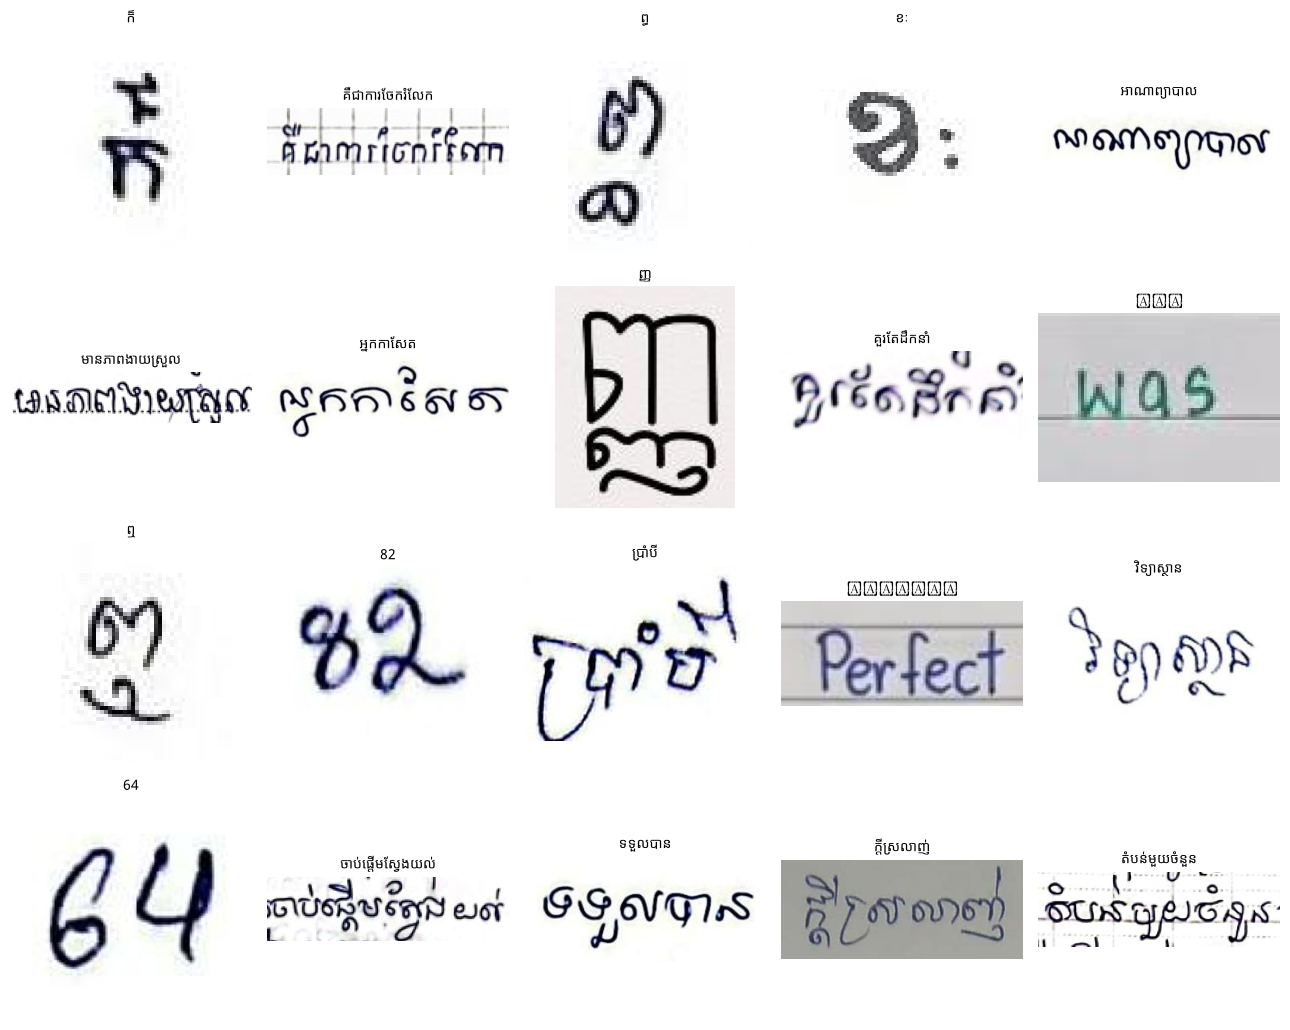

In [4]:
import warnings

sample_df = splits["trainset"].sample(n=20, random_state=0).reset_index(drop=True)

fig, axes = plt.subplots(4, 5, figsize=(5 * 2.6, 4 * 2.6))
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Glyph .* missing from font", category=UserWarning)
    for ax, (_, row) in zip(axes.ravel(), sample_df.iterrows()):
        ax.imshow(to_pil_image(row["image"]), cmap="gray")
        ax.set_title(row["text"], fontsize=11, fontproperties=khmer_prop)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## Text length distribution (1–50 characters)

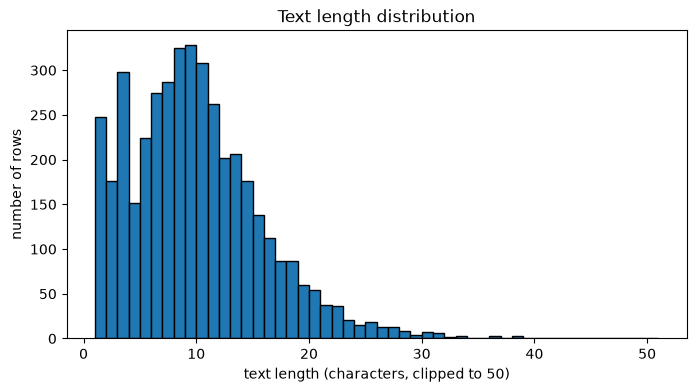

In [5]:
lengths = all_df["text"].fillna("").str.len()
lengths = lengths.clip(upper=50)

plt.figure(figsize=(8, 4))
plt.hist(lengths, bins=range(1, 52), edgecolor="black")
plt.xlabel("text length (characters, clipped to 50)")
plt.ylabel("number of rows")
plt.title("Text length distribution")
plt.show()

## Image width distribution

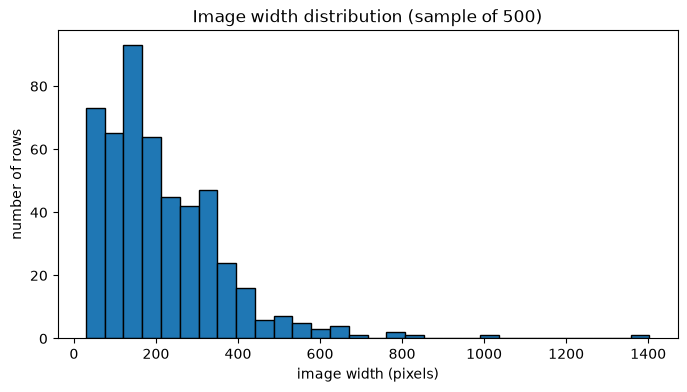

width min/mean/max: 29 / 215.8 / 1403


In [6]:
sample_n = 500
widths = []
for i in np.random.default_rng(0).choice(len(all_df), size=min(sample_n, len(all_df)), replace=False):
    img = to_pil_image(all_df.iloc[i]["image"])
    widths.append(img.size[0])
widths = np.array(widths)

plt.figure(figsize=(8, 4))
plt.hist(widths, bins=30, edgecolor="black")
plt.xlabel("image width (pixels)")
plt.ylabel("number of rows")
plt.title(f"Image width distribution (sample of {len(widths)})")
plt.show()

print(f"width min/mean/max: {widths.min()} / {widths.mean():.1f} / {widths.max()}")

## Rows containing English letters

In [7]:
has_latin = all_df["text"].fillna("").str.contains(LATIN_RE, regex=True)
print(f"rows with English letters: {has_latin.sum()} / {len(all_df)} ({has_latin.mean():.1%})")

for name, df in splits.items():
    split_has_latin = df["text"].fillna("").str.contains(LATIN_RE, regex=True)
    print(f"  {name:10s} {split_has_latin.sum():5d} / {len(df)}")

rows with English letters: 696 / 4202 (16.6%)
  trainset     514 / 3549
  valset        91 / 346
  testset       91 / 307
